In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from quantlab.data_loader import load_prices
from quantlab.returns import log_returns
from quantlab.diagnostics import moment_table, jarque_bera_table, tail_counts

prices = load_prices()
r = log_returns(prices)
print(r.shape, r.index[0].date(), r.index[-1].date())

(6537, 26) 2000-01-04 2025-12-30


In [3]:
moments = moment_table(r)
moments.round(3).sort_values("excess_kurt", ascending=False)

,mean_ann,vol_ann,skew,excess_kurt
Ticker,,,,
AAPL,0.223,0.398,-3.927,114.596
PG,0.065,0.211,-3.201,88.963
BAC,0.058,0.432,-0.333,27.646
WFC,0.088,0.373,0.607,23.543
HD,0.085,0.301,-1.067,23.411
UNH,0.160,0.317,-0.377,22.114
CVX,0.087,0.275,-0.472,19.734
JPM,0.102,0.368,0.213,14.668
PEP,0.078,0.200,-0.124,14.123


In [4]:
jb = jarque_bera_table(r)
print("Rejected Normality:", int(jb["reject"].sum()), "of", len(jb))
jb.head(10)

Rejected Normality: 1 of 26


,JB,p_value,reject
AAPL,3593721.424442,0.0,True
AMGN,10747.969391,0.0,True
AMZN,46514.260296,0.0,True
BAC,208296.037701,0.0,True
CAT,5830.148157,0.0,True
CSCO,29230.088683,0.0,True
CVX,106312.827199,0.0,True
DIS,25949.881316,0.0,True
GILD,16567.397807,0.0,True
HD,150527.76928,0.0,True


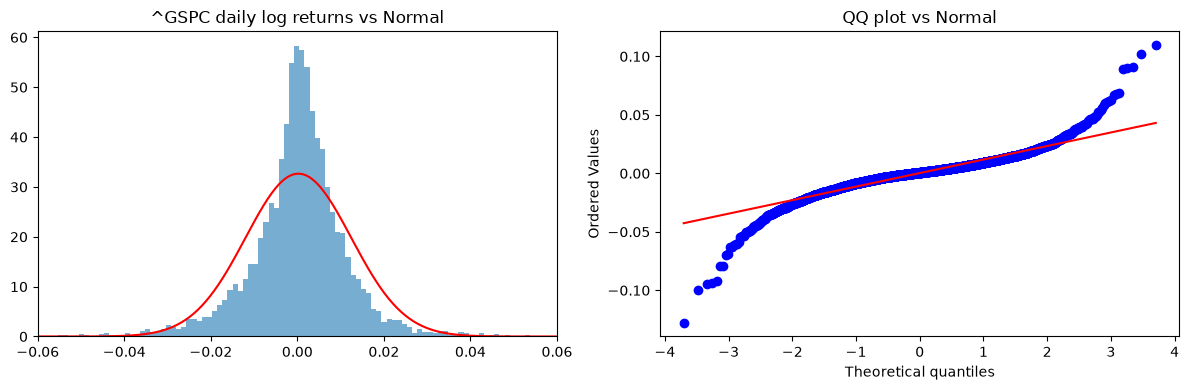

In [5]:
x = r["^GSPC"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(x, bins=200, density=True, alpha=0.6)
grid = np.linspace(x.min(), x.max(), 500)
ax[0].plot(grid, stats.norm.pdf(grid, x.mean(), x.std()), "r")
ax[0].set_xlim(-0.06, 0.06)
ax[0].set_title("^GSPC daily log returns vs Normal")

stats.probplot(x, dist="norm", plot=ax[1])
ax[1].set_title("QQ plot vs Normal")
plt.tight_layout()
plt.show()

In [8]:
tails = tail_counts(r, k=4)
print(f"Normal expects {tails['expected'].iloc[0]:.2f} days beyond 4 sigma per ticker")
tails.sort_values("observed", ascending=False).round(2)

Normal expects 0.41 days beyond 4 sigma per ticker


,observed,expected,ratio
Ticker,,,
WFC,64,0.41,154.56
BAC,60,0.41,144.90
ORCL,60,0.41,144.90
WMT,60,0.41,144.90
GILD,57,0.41,137.66
AMZN,57,0.41,137.66
CSCO,55,0.41,132.83
JPM,53,0.41,128.00
NKE,50,0.41,120.75


## Conclusions

**1. Highest excess kurtosis.** AAPL (114.6) and PG (89.0) are far above the rest, and both also have strongly negative skew (-3.9 and -3.2). Each seems to be driven by one or two enormous single-day drops in 2000 (AAPL's profit warning in September 2000, PG's warning in March 2000) rather than by many moderate ones. BAC (27.6), WFC (23.5), HD (23.4), UNH (22.1) and CVX (19.7) come next. For the banks the likely cause is the 2008-09 financial crisis. For the others it is probably a mix of 2008, March 2020 and company-specific news. The S&P 500 itself has excess kurtosis of 10.6, so even a diversified index is far from Normal. A Normal would score 0.

**2. Jarque-Bera.** All 26 series reject Normality; every p-value is 0.0. This is not surprising: with about 6,500 daily observations the test can detect very small departures. But here it is not a marginal call. The statistics are in the thousands to millions (smallest CAT about 5,800, AAPL about 3.6 million), against a 5% critical value of about 6. The departures from Normal are large.

**3. 4-sigma days.** A Normal predicts about 0.41 such days per ticker in 26 years. The real series have between 27 (AAPL) and 64 (WFC), which is roughly 65 to 155 times more than predicted. The S&P 500 has 43, about 104 times more. AAPL ranks first on kurtosis but last on 4-sigma days because its few huge moves inflate its standard deviation, which makes ordinary big days look smaller in comparison.

**4. Why fat tails matter for mean-variance optimisation.** The method uses only means and covariances. It ignores skewness and tail risk, so a portfolio that looks low-variance can still be exposed to rare large losses. Variance and covariance are also estimated from a few extreme days, so one event can shift the estimates a lot, and the optimiser tends to put large weights on exactly the assets whose estimates are most noisy. Correlations also tend to rise in a crisis, so diversification benefits shown by the full-sample covariance can disappear when they are needed. This leads directly to the estimation-error part of the project.